# Tentativo 16 · 1. Data preparation

**Obiettivo**: un dataset di articoli di testate **politiche**, ognuno con il livello e il **punteggio NewsGuard 2026**
(0–100), pulito in modo semplice e giustificabile, **senza testate parenti**. Le regole, fissate prima dei risultati:

1. **solo testate politiche** con un punteggio NewsGuard 2026, e solo lo **scraping di ottobre 2026**;
2. il testo di ogni articolo è **estratto dalla pagina HTML con trafilatura in modalità precisione** (Barbaresi 2021),
   senza altre regole di pulizia scritte da noi;
3. solo inglese, **tra 100 e 1.500 parole** (così ogni articolo entra intero in 2.048 token di ModernBERT), pubblicati
   dal 2025;
4. **doppioni e quasi doppioni** tolti tra **tutte** le testate (si tiene la copia più vecchia);
5. almeno 10 articoli per testata;
6. **una sola testata per gruppo** di testate parenti secondo NewsGuard 2026 (stesso Owner o stesso Parent Domain):
   così due testate parenti non possono mai stare una nel training e una nel test;
7. 5 fold stratificati per livello.

In [1]:
N_JOBS = 32            # processi in parallelo
TESTATE = 0            # 0 = tutte; un numero = prova veloce su quel numero di testate politiche a caso
SOGLIA = 0.5           # quasi doppioni: somiglianza (Jaccard dei 5-grammi di parole) da cui due articoli sono "lo stesso"
MIN_PAROLE = 100
MAX_PAROLE = 1500      # circa 2.000 token di ModernBERT (1,32 token per parola): ogni articolo entra intero in 2.048
MIN_ARTICOLI = 10
DAL = "2025-01-01"

In [2]:
import hashlib
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedKFold

import funzioni as F

warnings.filterwarnings("ignore")
DATI = F.DATI                             # la cartella unica dei dati (Dataset/ nella radice del repo)
GIRI = [DATI / "scraping" / "NuovoScraping_ottobre", DATI / "scraping" / "NuovoScraping_giro3"]     # lo scraping di ottobre 2026 (due giri)
OUT = Path("Results/dataset") / ("prova" if TESTATE else "")             # grafici e tabelle
DATASET = F.DATASET / ("prova" if TESTATE else ""); DATASET.mkdir(parents=True, exist_ok=True)   # il dataset
GRAFICI = OUT / "grafici"; GRAFICI.mkdir(parents=True, exist_ok=True)
CACHE = DATASET / "cache"; CACHE.mkdir(parents=True, exist_ok=True)

BLU, ARANCIO, VERDE, GRIGIO = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
    "patch.force_edgecolor": True, "patch.edgecolor": "#fcfcfb", "patch.linewidth": 0.6,
})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 100)

passi = []
def passo(nome, df):
    """Annota e stampa quanti articoli e testate restano dopo un passo."""
    tolti = passi[-1]["articoli"] - len(df) if passi else 0
    passi.append({"passo": nome, "articoli": len(df), "testate": df.domain.nunique()})
    print(f"→ restano {len(df):,} articoli di {df.domain.nunique():,} testate (tolti {tolti:,} articoli)")

def mostra(nome, griglia="y"):
    """Mostra il grafico (griglia solo sull'asse dei valori) e lo salva anche in PNG, per le slide."""
    for a in plt.gcf().axes:
        a.grid(False); a.grid(axis=griglia)
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

def barre(serie, titolo, nome, figsize=(8, 2.6)):
    """Barre orizzontali con il numero scritto in fondo a ogni barra."""
    serie = serie[::-1]
    plt.figure(figsize=figsize); plt.barh(serie.index, serie, color=BLU)
    for y, v in enumerate(serie):
        plt.text(v, y, f" {v:,}", va="center", fontsize=8, color=GRIGIO)
    plt.title(titolo); plt.gca().xaxis.set_major_formatter("{x:,.0f}"); mostra(nome, "x")

## 1. Da dove partiamo: le testate politiche

**NewsGuard 2026** dà a ogni testata un punteggio (0–100) e ne indica gli argomenti. A ottobre 2026 abbiamo fatto lo
scraping di una parte di queste testate, salvando per ogni articolo la pagina HTML. Teniamo solo le testate
**politiche**: un solo argomento, "Political news or commentary", e un punteggio.

In [3]:
# 1.1 NewsGuard 2026 e l'esito dello scraping (un file di stato per testata)
n26 = F.leggi_newsguard(DATI / "etichette" / "newsguard_2026.csv")
stati = pd.concat([F.leggi_stati([g]) for g in GIRI], ignore_index=True)
argomenti = stati.dominio.map(n26.Topics).fillna("").str.split(",").map(lambda x: [a.strip() for a in x if a.strip()])
stati["politica"] = (argomenti.map(lambda x: x == [F.POLITICA]) & stati.dominio.map(n26.Score).notna()).to_numpy()
politiche = sorted(stati.dominio[stati.politica])
if TESTATE:
    politiche = sorted(pd.Series(politiche).sample(TESTATE, random_state=F.SEED))
print(f"testate con un punteggio NewsGuard 2026: {n26.Score.notna().sum():,}; cercate con lo scraping: {len(stati):,}; "
      f"di cui politiche: {stati.politica.sum():,}")

testate con un punteggio NewsGuard 2026: 11,564; cercate con lo scraping: 5,113; di cui politiche: 1,293


## 2. Il testo: trafilatura in modalità precisione

Per ogni articolo riprendiamo la **pagina HTML salvata** e ne estraiamo il testo principale con trafilatura in modalità
**precisione** (`favor_precision=True`, senza commenti, tabelle, immagini, link e formattazione): trafilatura preferisce
lasciare fuori un paragrafo dubbio piuttosto che tenere menu, didascalie e pezzi di pagina. Nessun'altra regola di
pulizia: il testo è quello che restituisce trafilatura. Titolo, data e autore vengono dallo scraping.

In [4]:
# 2.1 riestrazione di tutti gli articoli delle testate politiche (in parallelo, una testata per processo)
f = CACHE / "estratti.csv.gz"
if f.exists():
    grezzo = pd.read_csv(f)
else:
    righe = Parallel(n_jobs=N_JOBS)(delayed(F.estrai_testata)(d, GIRI) for d in politiche)
    grezzo = pd.DataFrame([r for rr in righe for r in rr])
    grezzo.to_csv(f, index=False)
grezzo["parole_scraping"] = grezzo.testo_scraping.fillna("").str.split().str.len()
grezzo["parole"] = grezzo.text.fillna("").str.split().str.len()
print(f"{len(grezzo):,} articoli di {grezzo.domain.nunique():,} testate; con la pagina HTML: {grezzo.ha_html.mean():.1%}; "
      f"testo estratto: {grezzo.text.notna().mean():.1%}")
print(f"parole in tutto: {grezzo.parole_scraping.sum():,} con lo scraping, {grezzo.parole.sum():,} con trafilatura in precisione "
      f"({grezzo.parole.sum() / grezzo.parole_scraping.sum() - 1:+.1%})")

86,225 articoli di 674 testate; con la pagina HTML: 100.0%; testo estratto: 98.9%
parole in tutto: 66,803,106 con lo scraping, 64,263,233 con trafilatura in precisione (-3.8%)


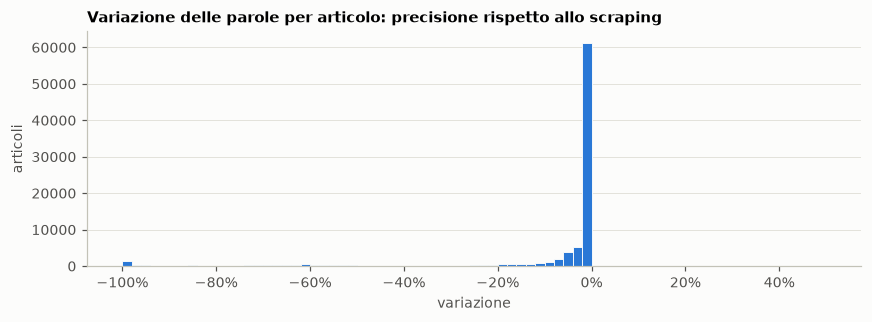

quasi invariati (±10%): 85.6%; perdono più del 10%: 13.9%; perdono più di metà del testo: 7.2%


In [5]:
# 2.2 quanto testo cambia per articolo rispetto allo scraping (trafilatura standard)
cambio = (grezzo.parole - grezzo.parole_scraping)[grezzo.parole_scraping > 0] / grezzo.parole_scraping[grezzo.parole_scraping > 0]
plt.hist(cambio.clip(-1, 0.5), bins=np.arange(-1, 0.52, 0.02), color=BLU)
plt.title("Variazione delle parole per articolo: precisione rispetto allo scraping"); plt.xlabel("variazione"); plt.ylabel("articoli")
plt.gca().xaxis.set_major_formatter("{x:.0%}")
mostra("2_variazione")
print(f"quasi invariati (±10%): {cambio.abs().le(0.1).mean():.1%}; perdono più del 10%: {(cambio < -0.1).mean():.1%}; "
      f"perdono più di metà del testo: {(cambio < -0.5).mean():.1%}")

In [6]:
# 2.3 senza testo estratto (pagina mancante o trafilatura non trova un testo principale): fuori
art = grezzo[grezzo.text.notna()].reset_index(drop=True)
passi.append({"passo": "1. articoli delle testate politiche", "articoli": len(grezzo), "testate": grezzo.domain.nunique()})
passo("2. con testo estratto da trafilatura", art)

→ restano 85,303 articoli di 668 testate (tolti 922 articoli)


## 3. Filtri sugli articoli: inglese, lunghezza, data

La lunghezza ha due soglie: almeno **100 parole** (via pagine di servizio e brevi) e al più **1.500 parole**. Sopra
quella soglia ci sono soprattutto testi di altro genere (rapporti, studi, saggi lunghi, trascrizioni di podcast); e con
1.500 parole (circa 2.000 token) ogni articolo entra intero nella finestra di 2.048 token di ModernBERT, così tutti i
modelli leggono tutto il testo.

In [7]:
# 3.1 solo inglese (riconoscimento automatico della lingua sulle prime 400 parole)
art = art.assign(lingua=Parallel(n_jobs=N_JOBS, batch_size=200)(delayed(F.lingua)(t) for t in art.text))
display(art.lingua.value_counts().head(6).rename("articoli").to_frame().T)
art = art[art.lingua == "en"]
passo("3.1 in inglese", art)

lingua,en,de,fr,it,ru,vi
articoli,67231,9536,4699,1529,1109,401


→ restano 67,231 articoli di 577 testate (tolti 18,072 articoli)


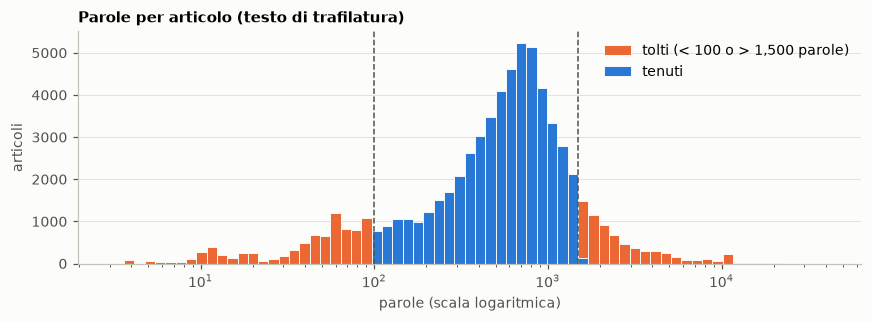

sotto 100: 8,531 articoli; sopra 1,500: 6,673 articoli
→ restano 52,027 articoli di 565 testate (tolti 15,204 articoli)


In [8]:
# 3.2 tra MIN_PAROLE e MAX_PAROLE parole
dentro = art.parole.between(MIN_PAROLE, MAX_PAROLE)
bins = np.logspace(0.5, 4.6, 70)
plt.hist(art.parole[~dentro].clip(lower=4), bins, color=ARANCIO, label=f"tolti (< {MIN_PAROLE} o > {MAX_PAROLE:,} parole)")
plt.hist(art.parole[dentro], bins, color=BLU, label="tenuti")
plt.xscale("log"); plt.legend()
for x in [MIN_PAROLE, MAX_PAROLE]:
    plt.axvline(x, color=GRIGIO, ls="--", lw=1)
plt.title("Parole per articolo (testo di trafilatura)"); plt.xlabel("parole (scala logaritmica)"); plt.ylabel("articoli")
mostra("3_parole")
print(f"sotto {MIN_PAROLE}: {(art.parole < MIN_PAROLE).sum():,} articoli; sopra {MAX_PAROLE:,}: {(art.parole > MAX_PAROLE).sum():,} articoli")
art = art[dentro]
passo(f"3.2 tra {MIN_PAROLE} e {MAX_PAROLE:,} parole", art)

In [9]:
# 3.3 pubblicati dal 2025 (il periodo delle etichette NewsGuard 2026)
art["data"] = pd.to_datetime(art.data, errors="coerce")
anno = art.data.dt.year
per_anno = anno[anno >= 2015].astype(int).value_counts().sort_index()
display(pd.concat([pd.Series({"senza data": anno.isna().sum(), "prima del 2015": (anno < 2015).sum()}), per_anno]).rename("articoli").to_frame().T)
art = art[art.data >= DAL].reset_index(drop=True).rename_axis("article_id").reset_index()       # da qui ogni articolo ha un numero
passo(f"3.3 pubblicati dal {DAL[:4]}", art)

,senza data,prima del 2015,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
articoli,1,1977,132,414,558,402,742,1158,1094,1847,1493,1977,3846,36386


→ restano 40,232 articoli di 531 testate (tolti 11,795 articoli)


## 4. Doppioni e quasi doppioni, tra tutte le testate

Lo stesso testo non deve comparire due volte, né nella stessa testata né in testate diverse (articoli di agenzia
ripubblicati, siti che si copiano). Di ogni gruppo di copie si tiene **la più vecchia**.

- **doppioni**: lo stesso testo, a meno di maiuscole, punteggiatura e spazi;
- **quasi doppioni**: somiglianza di Jaccard tra i 5-grammi di parole almeno **SOGLIA** (stima MinHash). Il grafico
  mostra tutte le coppie sopra 0,3, per vedere dove cade la soglia.

In [10]:
# 4.1 doppioni: stessa impronta del testo normalizzato
art["norm"] = art.text.map(F.normalizza)
art["impronta"] = art.norm.map(lambda s: hashlib.md5(s.encode()).hexdigest())
copie_esatte = art.impronta.duplicated(keep=False)
print(f"articoli con almeno un doppione: {copie_esatte.sum():,}; di questi in testate diverse: "
      f"{(art[copie_esatte].groupby('impronta').domain.nunique() > 1).sum():,} gruppi di copie")
art = art.sort_values(["data", "article_id"]).drop_duplicates("impronta").sort_values("article_id")
passo("4.1 senza doppioni", art)

articoli con almeno un doppione: 8,101; di questi in testate diverse: 2,652 gruppi di copie
→ restano 34,799 articoli di 361 testate (tolti 5,433 articoli)


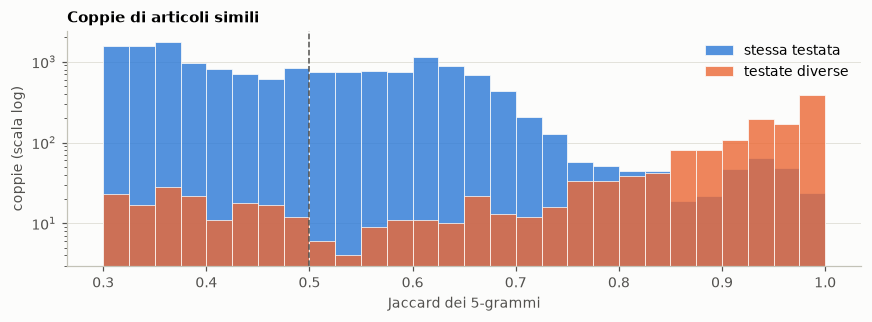

tra,stessa testata,testate diverse
coppie sopra la soglia,7120,1283


→ restano 33,694 articoli di 347 testate (tolti 1,105 articoli)


In [11]:
# 4.2 quasi doppioni: coppie con somiglianza alta (MinHash), poi un gruppo per ogni insieme di copie collegate
coppie = F.coppie_simili(art.reset_index(drop=True), 0.3, N_JOBS)
coppie["tra"] = np.where(coppie.testata_a == coppie.testata_b, "stessa testata", "testate diverse")
bins = np.arange(0.3, 1.0001, 0.025)
for k, colore in [("stessa testata", BLU), ("testate diverse", ARANCIO)]:
    plt.hist(coppie.jaccard[coppie.tra == k], bins, color=colore, alpha=0.8, label=k)
plt.axvline(SOGLIA, color=GRIGIO, ls="--", lw=1); plt.yscale("log"); plt.legend()
plt.title("Coppie di articoli simili"); plt.xlabel("Jaccard dei 5-grammi"); plt.ylabel("coppie (scala log)")
mostra("4_quasi_doppioni")

copie = coppie[coppie.jaccard >= SOGLIA]
G = nx.Graph(); G.add_edges_from(zip(copie.articolo_a, copie.articolo_b))
data = art.set_index("article_id").data
via = {x for fam in nx.connected_components(G) for x in sorted(fam, key=lambda x: (data[x], x))[1:]}
display(copie.tra.value_counts().rename("coppie sopra la soglia").to_frame().T)
art = art[~art.article_id.isin(via)]
passo(f"4.2 senza quasi doppioni (Jaccard ≥ {SOGLIA})", art)

In [12]:
# 4.3 le testate che si copiavano: quante sono ancora nel dataset (servirà come controllo, sezione 6)
tra = copie[copie.tra == "testate diverse"]
legami = pd.Series([tuple(sorted(p)) for p in zip(tra.testata_a, tra.testata_b)]).value_counts()     # coppia di testate → copie
print(f"coppie di testate che condividevano almeno un articolo quasi uguale: {len(legami):,}")

coppie di testate che condividevano almeno un articolo quasi uguale: 161


## 5. Testate con abbastanza articoli

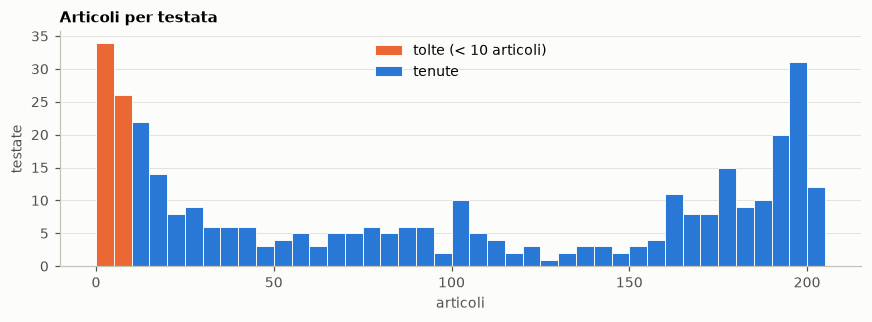

→ restano 33,443 articoli di 287 testate (tolti 251 articoli)


In [13]:
# 5.1 almeno MIN_ARTICOLI articoli per testata
quanti = art.groupby("domain").size()
bins = np.arange(0, 210, 5)
plt.hist(quanti[quanti < MIN_ARTICOLI], bins, color=ARANCIO, label=f"tolte (< {MIN_ARTICOLI} articoli)")
plt.hist(quanti[quanti >= MIN_ARTICOLI], bins, color=BLU, label="tenute"); plt.legend()
plt.title("Articoli per testata"); plt.xlabel("articoli"); plt.ylabel("testate")
mostra("5_articoli_per_testata")
art = art[art.domain.isin(quanti.index[quanti >= MIN_ARTICOLI])]
passo(f"5.1 testate con almeno {MIN_ARTICOLI} articoli", art)

## 6. Una sola testata per gruppo di testate parenti

Due testate sono **parenti** se per NewsGuard 2026 hanno **lo stesso proprietario** (Owner, con il nome normalizzato:
senza "Inc", "LLC", "Media"…) o **lo stesso Parent Domain**; un gruppo = testate parenti, anche indirettamente. Di ogni
gruppo teniamo **una sola testata: quella con più articoli** (a parità, la prima in ordine alfabetico). È una regola che
non guarda le etichette, e toglie alla radice il rischio che il modello riconosca nel test una testata "sorella" vista
nel training.

In [14]:
# 6.1 i gruppi da Owner e Parent Domain (NewsGuard 2026)
testate = sorted(art.domain.unique())
G = nx.Graph(); G.add_nodes_from(testate)
owner = pd.Series({d: F.normalizza_owner(n26.Owner.get(d, "")) for d in testate})
parent = pd.Series({d: str(n26["Parent Domain"].get(d, "")).strip().lower() for d in testate}).replace("nan", "")
for valore in [owner, parent]:
    v = valore[valore != ""]
    for _, stessi in v.groupby(v):
        G.add_edges_from(zip(stessi.index, stessi.index[1:]))
gruppo = {d: i for i, c in enumerate(sorted(nx.connected_components(G), key=len, reverse=True)) for d in c}
art["gruppo"] = art.domain.map(gruppo)
dimensione = pd.Series(gruppo).value_counts()
print(f"{len(dimensione)} gruppi per {len(testate)} testate; gruppi con più testate: {(dimensione > 1).sum()} (il più grande: {dimensione.max()})")

righe = []
for g in dimensione.index[dimensione > 1][:10]:
    membri = sorted((d for d, x in gruppo.items() if x == g), key=lambda d: (-quanti[d], d))
    righe.append({"testate": len(membri), "Owner": n26.Owner.get(membri[0], ""), "Parent Domain": n26["Parent Domain"].get(membri[0], ""),
                  "tenuta": membri[0], "tolte (esempi)": ", ".join(membri[1:4]) + (", …" if len(membri) > 4 else "")})
pd.DataFrame(righe)

226 gruppi per 287 testate; gruppi con più testate: 20 (il più grande: 18)


,testate,Owner,Parent Domain,tenuta,tolte (esempi)
0,18,FiveZero Media,rightwinginsider.com,beyondnews.org,"watchdognews.org, mainstpress.com, therecorddaily.com, …"
1,15,Good Information Inc.,NaN,granitepostnews.com,"keystonenewsroom.com, iowastartingline.com, coppercourier.com, …"
2,7,Salem Media Group,NaN,twitchy.com,"redstate.com, townhall.com, pjmedia.com, …"
3,6,American Independent Media,tainews.com,alaskaindependentnews.com,"jerseyindependent.com, michiganindependent.com, pennsylvaniaindependent.com, …"
4,5,"Righters Group, LLC",rightnewswire.com,desantisdaily.com,"patriotpulse.net, unmuzzlednews.com, conservativeundergroundnews.com, …"
5,2,"SSP Organization, LLC",100percentfedup.com,100percentfedup.com,wltreport.com
6,2,Alpha News,alphanews.org,alphanews.org,alphanewsmn.com
7,2,AlterNet Media Inc.,NaN,alternet.org,thenewcivilrightsmovement.com
8,2,Ryan Mauldin,americanjournaldaily.com,americanjournaldaily.com,pjnewsletter.com
9,2,Creative Destruction Media LLC,cdm.press,cdm.press,creativedestructionmedia.com


In [15]:
# 6.2 di ogni gruppo si tiene la testata con più articoli
tenute = (art.groupby("domain").agg(gruppo=("gruppo", "first"), articoli=("article_id", "size")).reset_index()
          .sort_values(["articoli", "domain"], ascending=[False, True]).groupby("gruppo").head(1).domain)
art = art[art.domain.isin(tenute)]
passo("6.2 una testata per gruppo", art)
rimaste = [p for p in legami.index if p[0] in set(tenute) and p[1] in set(tenute)]
print(f"controllo: coppie di testate rimaste che si copiavano articoli (prima di togliere i quasi doppioni): {len(rimaste)}")

→ restano 25,524 articoli di 226 testate (tolti 7,919 articoli)
controllo: coppie di testate rimaste che si copiavano articoli (prima di togliere i quasi doppioni): 38


## 7. Le etichette e i fold

Ogni articolo riceve il **punteggio NewsGuard 2026** della sua testata (0–100) e il **livello** che ne deriva
(l1 < 40, l2 40–59, l3 60–74, l4 75–99, l5 = 100; affidabile = punteggio ≥ 60, cioè l3–l5). Poi **5 fold** di testate,
stratificati per livello: tutti gli articoli di una testata stanno nello stesso fold. Non servono gruppi: ogni testata è
già l'unica del suo gruppo.

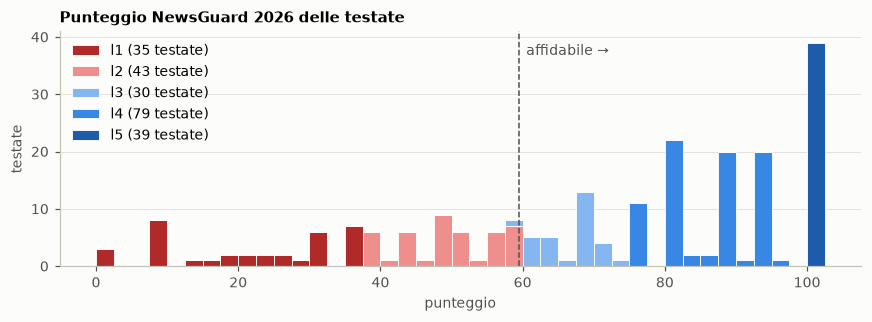

In [16]:
# 7.1 punteggio e livello su ogni articolo
art["score"] = art.domain.map(n26.Score).astype(float)
art["label"] = F.livello(art.score)
art["livello"] = art.label.map(dict(enumerate(F.LIVELLI)))
t = art.groupby("domain").agg(score=("score", "first"), label=("label", "first"), livello=("livello", "first"), articoli=("article_id", "size"))
t["orientamento"] = t.index.map(n26.Orientation).fillna("nessuno")

plt.hist([t.score[t.label == k] for k in range(5)], np.arange(0, 102.6, 2.5), stacked=True, color=COLORE_LIVELLO,
         label=[f"{l} ({(t.label == k).sum()} testate)" for k, l in enumerate(F.LIVELLI)])
plt.axvline(59.5, color=GRIGIO, ls="--", lw=1); plt.text(60.5, plt.ylim()[1] * 0.9, "affidabile →", color=GRIGIO)
plt.title("Punteggio NewsGuard 2026 delle testate"); plt.xlabel("punteggio"); plt.ylabel("testate"); plt.legend()
mostra("7_punteggi")

In [17]:
# 7.2 i 5 fold, stratificati per livello
t["fold"] = 0
for k, (_, test) in enumerate(StratifiedKFold(5, shuffle=True, random_state=F.SEED).split(t, t.label), 1):
    t.iloc[test, t.columns.get_loc("fold")] = k
art["fold"] = art.domain.map(t.fold)
pd.crosstab(t.fold, t.livello, margins=True, margins_name="totale")

livello,l1,l2,l3,l4,l5,totale
fold,,,,,,
1,7,9,6,16,8,46
2,7,9,6,16,7,45
3,7,8,6,16,8,45
4,7,8,6,16,8,45
5,7,9,6,15,8,45
totale,35,43,30,79,39,226


### Il dataset finale

In [18]:
# 7.3 testate e articoli per livello
finale = pd.DataFrame({"punteggio": ["0–39", "40–59", "60–74", "75–99", "100"],
                       "testate": t.livello.value_counts().reindex(F.LIVELLI), "articoli": art.livello.value_counts().reindex(F.LIVELLI),
                       "articoli per testata (mediana)": t.groupby("livello").articoli.median().reindex(F.LIVELLI)}, index=F.LIVELLI)
display(finale)
pd.crosstab(t.orientamento, t.livello, margins=True, margins_name="totale")

,punteggio,testate,articoli,articoli per testata (mediana)
l1,0–39,35,4357,164.0
l2,40–59,43,5431,169.0
l3,60–74,30,3464,110.5
l4,75–99,79,7962,90.0
l5,100,39,4310,108.0


livello,l1,l2,l3,l4,l5,totale
orientamento,,,,,,
Left,3,8,6,37,14,68
Right,28,30,17,20,4,99
nessuno,4,5,7,22,21,59
totale,35,43,30,79,39,226


## 8. Quanta "sporcizia" resta?

Non togliamo nient'altro a mano, ma **misuriamo**: per alcune espressioni tipiche di pezzi di pagina, la quota di
articoli del dataset finale che le contengono, nel testo dello scraping (trafilatura standard) e nel testo usato
(trafilatura in precisione). Alcune possono comparire anche in un testo normale (*subscribe*, *copyright*): è una
misura indicativa.

In [19]:
# 8.1 quota di articoli che contengono ogni espressione, prima e dopo
SPORCIZIA = {"crediti foto (Getty Images, AP Photo, Shutterstock…)": r"getty images|ap photo|shutterstock|photo credit|\(photo:",
             "rimandi (Also read, Read more, Related)": r"\balso read\b|\bread more\b|\bread also\b|\brelated:",
             "iscrizioni e newsletter": r"\bsubscribe\b|\bnewsletter\b|\bsign up\b",
             "donazioni": r"\bdonate\b|\bdonation",
             "pubblicità": r"\badvertisement\b|\bsponsored\b",
             "diritti (©, all rights reserved)": r"©|all rights reserved",
             "social e condivisione": r"share this|follow us|click here|view this post on instagram|pic\.twitter\.com",
             "link e indirizzi web": r"https?://|www\.",
             "note della redazione": r"editor'?s note"}
residui = pd.DataFrame({k: {"scraping (standard)": art.testo_scraping.fillna("").str.contains(p, case=False, regex=True).mean(),
                            "dataset (precisione)": art.text.str.contains(p, case=False, regex=True).mean()} for k, p in SPORCIZIA.items()}).T
residui.to_csv(OUT / "sporcizia_residua.csv")
(residui * 100).round(1).astype(str) + "%"

,scraping (standard),dataset (precisione)
"crediti foto (Getty Images, AP Photo, Shutterstock…)",1.2%,0.8%
"rimandi (Also read, Read more, Related)",4.7%,3.8%
iscrizioni e newsletter,13.0%,11.0%
donazioni,6.7%,6.4%
pubblicità,3.4%,3.3%
"diritti (©, all rights reserved)",0.2%,0.2%
social e condivisione,11.4%,10.1%
link e indirizzi web,7.3%,6.0%
note della redazione,0.7%,0.7%


## 9. In breve e salvataggio

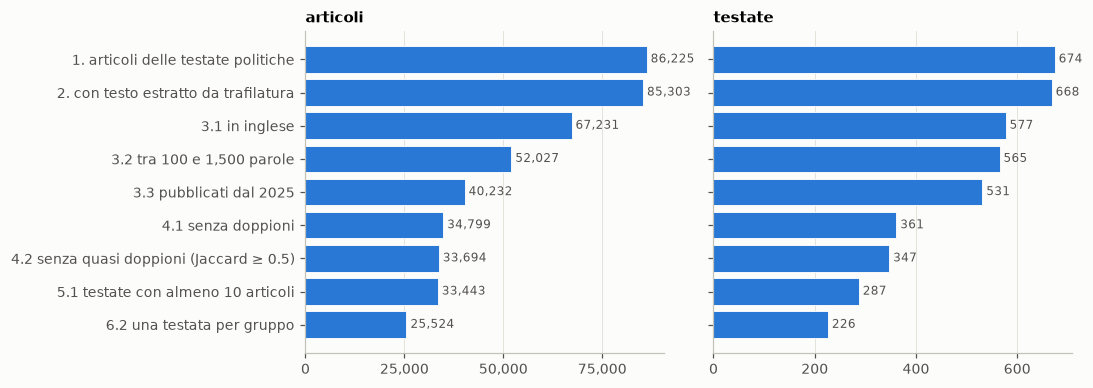

,articoli,testate
passo,,
1. articoli delle testate politiche,86225,674
2. con testo estratto da trafilatura,85303,668
3.1 in inglese,67231,577
"3.2 tra 100 e 1,500 parole",52027,565
3.3 pubblicati dal 2025,40232,531
4.1 senza doppioni,34799,361
4.2 senza quasi doppioni (Jaccard ≥ 0.5),33694,347
5.1 testate con almeno 10 articoli,33443,287
6.2 una testata per gruppo,25524,226


In [20]:
# 9.1 tutti i passi
p = pd.DataFrame(passi).set_index("passo")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, col in zip(ax, ["articoli", "testate"]):
    a.barh(p.index[::-1], p[col][::-1], color=BLU)
    a.set_title(col); a.xaxis.set_major_formatter("{x:,.0f}"); a.xaxis.set_major_locator(plt.MaxNLocator(4))
    for y, v in enumerate(p[col][::-1]):
        a.text(v, y, f" {v:,}", va="center", fontsize=8, color=GRIGIO)
mostra("9_riassunto", "x")
p

In [21]:
# 9.2 salvo il dataset per la classificazione
colonne = ["article_id", "domain", "url", "titolo", "data", "autore", "text", "score", "label", "livello", "fold"]
art[colonne].to_csv(DATASET / "articoli.csv.gz", index=False)
t.to_csv(DATASET / "testate.csv")
print(f"{len(art):,} articoli di {len(t)} testate → {DATASET}/articoli.csv.gz, testate.csv")

25,524 articoli di 226 testate → Results/dataset/articoli.csv.gz, testate.csv
